In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

In [2]:
G = nx.read_gexf("./graph.gexf", node_type=int)

# Node attributes are 'latitude', 'longitude', and 'geohash' label
print(G.nodes(data=True)[0])

{'lat': 41.2289428710938, 'long': 29.0753173828125, 'district': 0, 'continent': 0, 'highway': 1, 'population': 1920, 'label': 'sxkdt9'}


In [3]:
# Simple statistics

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

density = nx.density(G)
is_connected = nx.is_connected(G)

degrees = [deg for _, deg in G.degree()]
avg_degree = sum(degrees) / num_nodes
max_degree = max(degrees)
min_degree = min(degrees)

print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")
print(f"Density: {density:.4f}")
print(f"Is connected: {is_connected}")
print(f"Average degree: {avg_degree:.2f}")
print(f"Max degree: {max_degree}")
print(f"Min degree: {min_degree}")

Number of nodes: 2464
Number of edges: 3695
Density: 0.0012
Is connected: True
Average degree: 3.00
Max degree: 4
Min degree: 1


<center>
<img src="./figures/ibb_graph.png" width="70%">


In [4]:
# sensor records (i.e., traffic features)

records = pd.read_csv("./data/traffic_density_202301.csv")

In [5]:
# DATE_TIME         : date
# GEOHASH           : unique sensor id
# MINIMUM_SPEED     : minimum car speed recorded during that hour
# MAXIMUM_SPEED     : maximum car speed recorded during that hour
# AVERAGE_SPEED     : average car speed for that hour
# NUMBER_OF_VEHICLES: number of passing vehicles

# NOTE: if NUMBER_OF_VEHICLES is 0, then MINIMUM_SPEED, MAXIMUM_SPEED, and AVERAGE_SPEED is NaN. 
# You can fill these with mean of previous week/hour etc. (consider same sensor)

records.head()

,DATE_TIME,GEOHASH,MINIMUM_SPEED,MAXIMUM_SPEED,AVERAGE_SPEED,NUMBER_OF_VEHICLES
0,2023-01-01 00:00:00,sxkdt9,75.0,116.0,95.0,2.0
1,2023-01-01 00:00:00,sxk9e0,7.0,104.0,55.0,103.0
2,2023-01-01 00:00:00,sx7fvd,55.0,79.0,68.0,5.0
3,2023-01-01 00:00:00,sx7fvm,50.0,74.0,60.0,6.0
4,2023-01-01 00:00:00,sxk9qm,6.0,120.0,56.0,149.0


Text(0, 0.5, 'Average Speed')

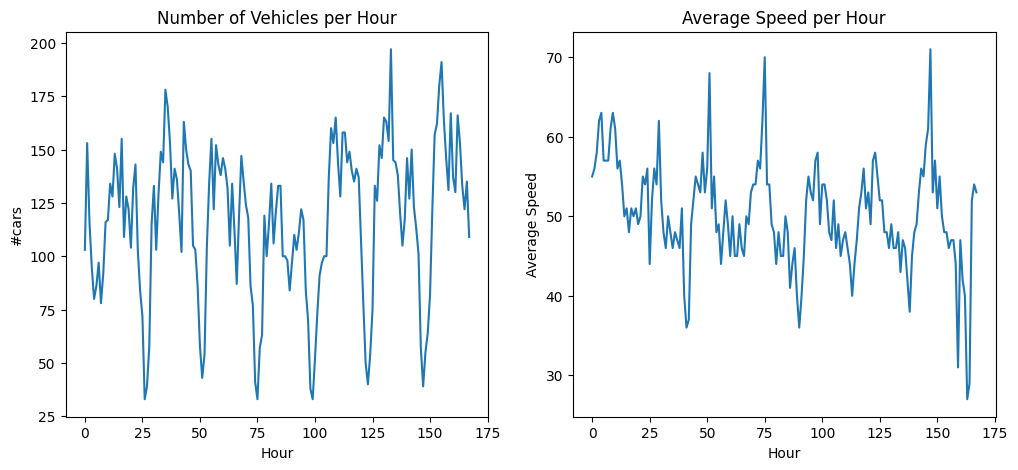

In [6]:
# For a random location/sensor (i.e., sxk9e0), traffic records for one week (168 hours)

num_vehicles = records.loc[records["GEOHASH"] == "sxk9e0"]["NUMBER_OF_VEHICLES"].values[:168]
avg_speed = records.loc[records["GEOHASH"] == "sxk9e0"]["AVERAGE_SPEED"].values[:168]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

axes[0].plot(num_vehicles)
axes[0].set_title('Number of Vehicles per Hour')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('#cars')

# Plot 2 (Right side)
axes[1].plot(avg_speed)
axes[1].set_title('Average Speed per Hour')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Average Speed')